# The Model That Doesn't Know: Out-of-Distribution Detection Study
### CodeChef-VIT Recruitment Task / AI & Machine Learning Track

**Objective**: Develop an image classification system that recognizes familiar categories while reliably identifying inputs that do not belong to any of its known classes — admitting uncertainty rather than making confident wrong predictions.

## 1. System Architecture & Controlled Splits
- **Backbone**: Frozen ImageNet ResNet-18 (512-dimensional penultimate representations).
- **Classifier**: Multinomial Logistic Regression head ($C=0.01$) trained strictly on 5 known classes.
- **In-Distribution (Known)**: CIFAR-10 `[Airplane, Automobile, Bird, Cat, Deer]`.
- **Near-OOD (Hard)**: CIFAR-10 Held-out `[Dog, Frog, Horse, Ship, Truck]` (semantic neighbors to known classes).
- **Far-OOD (Easy)**: FashionMNIST test set (10,000 grayscale clothing items).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

# Load quantitative metrics summary
with open("results/metrics.json") as f:
    results = json.load(f)

print(f"Closed-Set Known Test Accuracy: {results['closed_set']['test_accuracy']*100:.2f}%")
print(f"ECE Calibration: {results['calibration']['ece_before_temp_scaling']*100:.2f}% -> {results['calibration']['ece_after_temp_scaling']*100:.2f}% (T={results['calibration']['optimal_temperature']:.3f})")

Closed-Set Known Test Accuracy: 92.02%
ECE Calibration: 0.77% -> 0.79% (T=0.946)


## 2. Quantitative Detection Benchmark
Comparison of three distinct detector mechanisms across Near-OOD and Far-OOD regimes:

In [2]:
df = pd.DataFrame(results["metrics_table"])
df[["method", "ood_label", "auroc", "fpr_at_95tpr", "threshold"]]

,method,ood_label,auroc,fpr_at_95tpr,threshold
0,MSP,Near-OOD (CIFAR Held-out),0.7182,0.7456,-0.9991
1,MSP,Far-OOD (FashionMNIST),0.8677,0.3976,-0.9743
2,Energy,Near-OOD (CIFAR Held-out),0.7319,0.7330,-8.1295
3,Energy,Far-OOD (FashionMNIST),0.8972,0.3360,-5.2923
4,Mahalanobis,Near-OOD (CIFAR Held-out),0.6824,0.8056,19.7204
5,Mahalanobis,Far-OOD (FashionMNIST),0.9408,0.3206,23.8758


## 3. Visualization Gallery
### 3.1 Score Distributions (MSP vs Energy vs Mahalanobis)
Demonstrates the clear separation on Far-OOD (FashionMNIST) versus the overlapping feature manifold on Near-OOD (CIFAR Held-out).

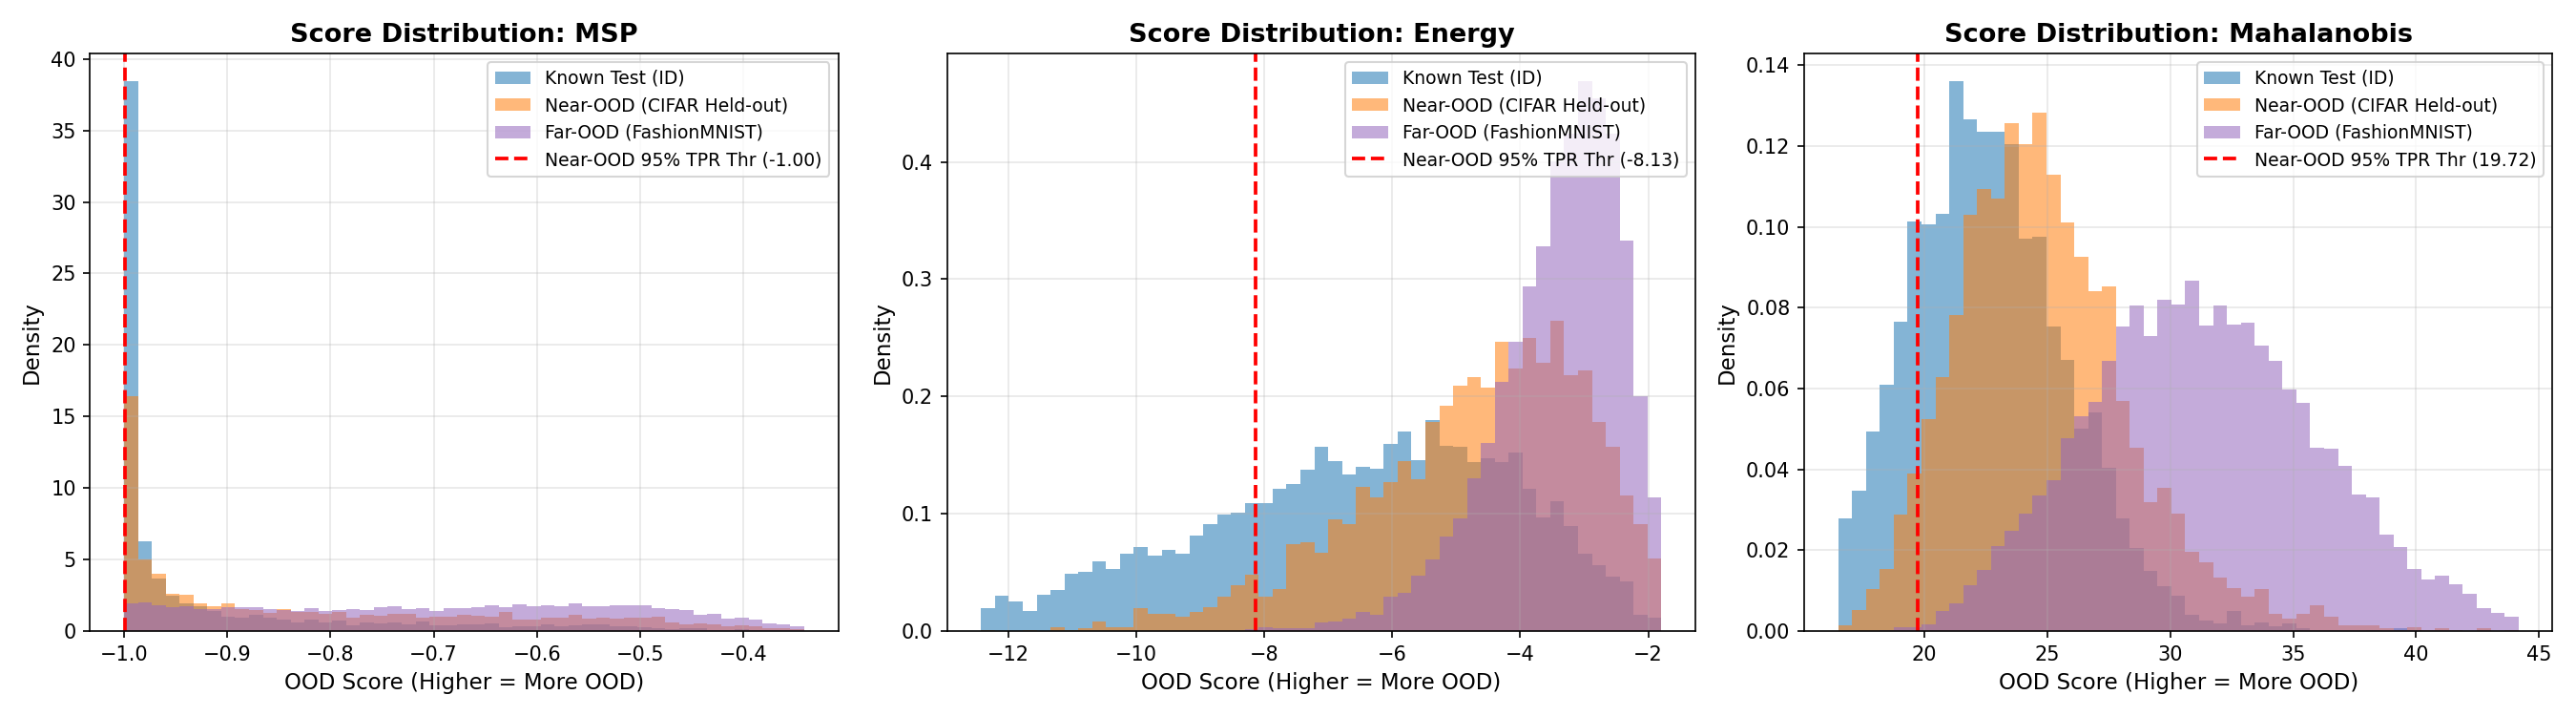

In [3]:
display(Image("figures/score_distributions.png"))

### 3.2 Selective Classification (Risk-Coverage Curves)
Direct validation of the task's premise: rejecting low-confidence predictions drastically improves accuracy on accepted inputs.

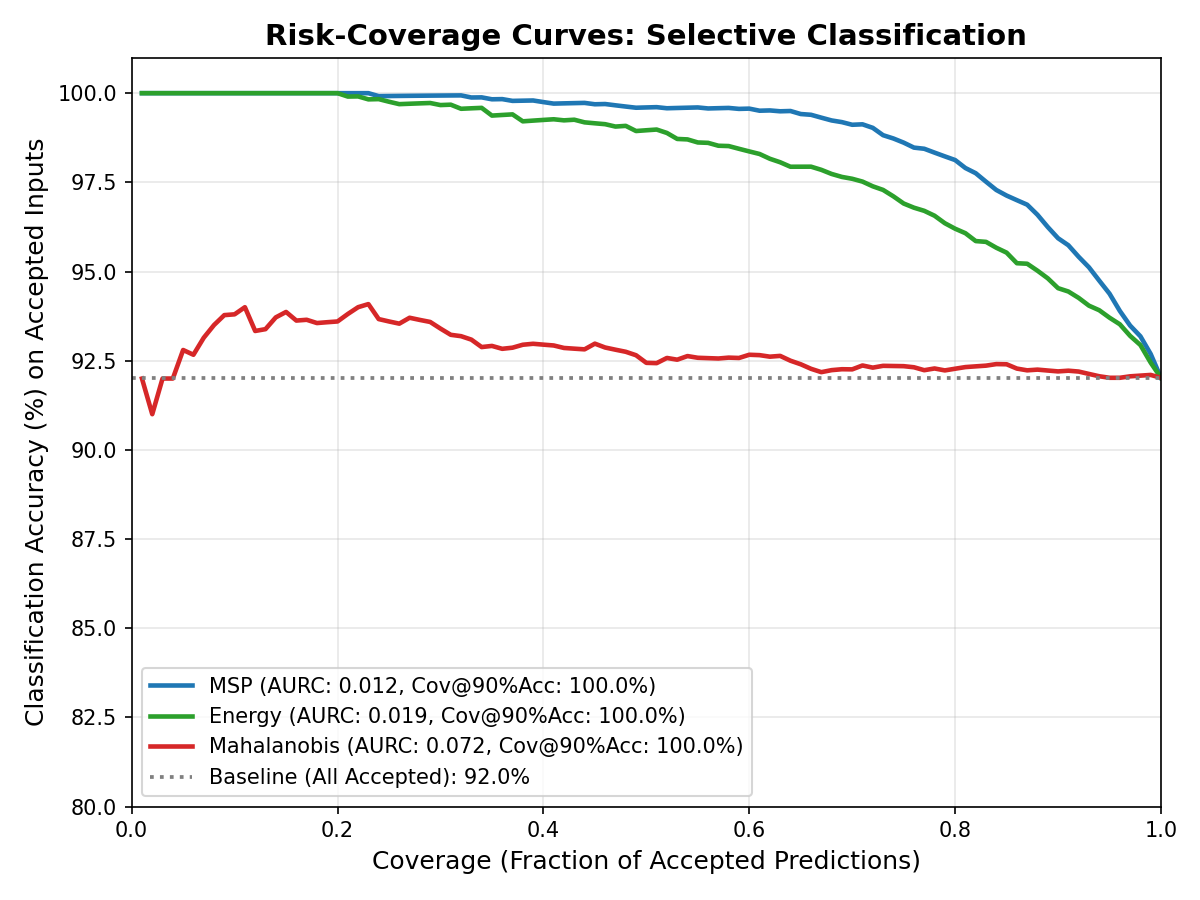

In [4]:
display(Image("figures/risk_coverage.png"))

### 3.3 Attractor Analysis: Per-Class AUROC
Shows which known classes are most vulnerable to confusing unknown inputs (e.g. Cat attracting Dog; Deer attracting Horse).

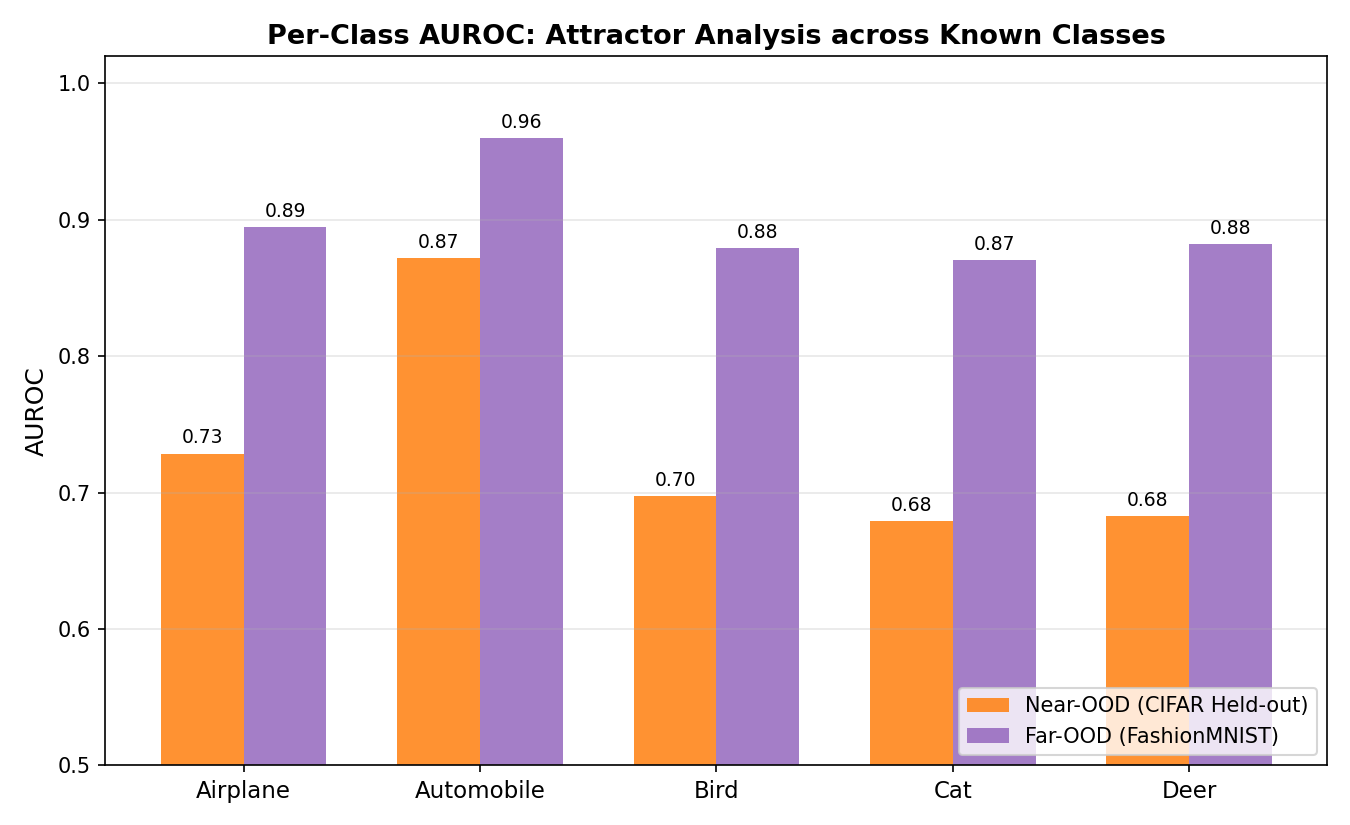

In [5]:
display(Image("figures/per_class_auroc.png"))

### 3.4 Failure Gallery: Falsely Accepted OOD Inputs at 95% TPR Threshold
A 5x5 grid of unknown images that slipped past the detector filter, annotated with predicted class and confidence.

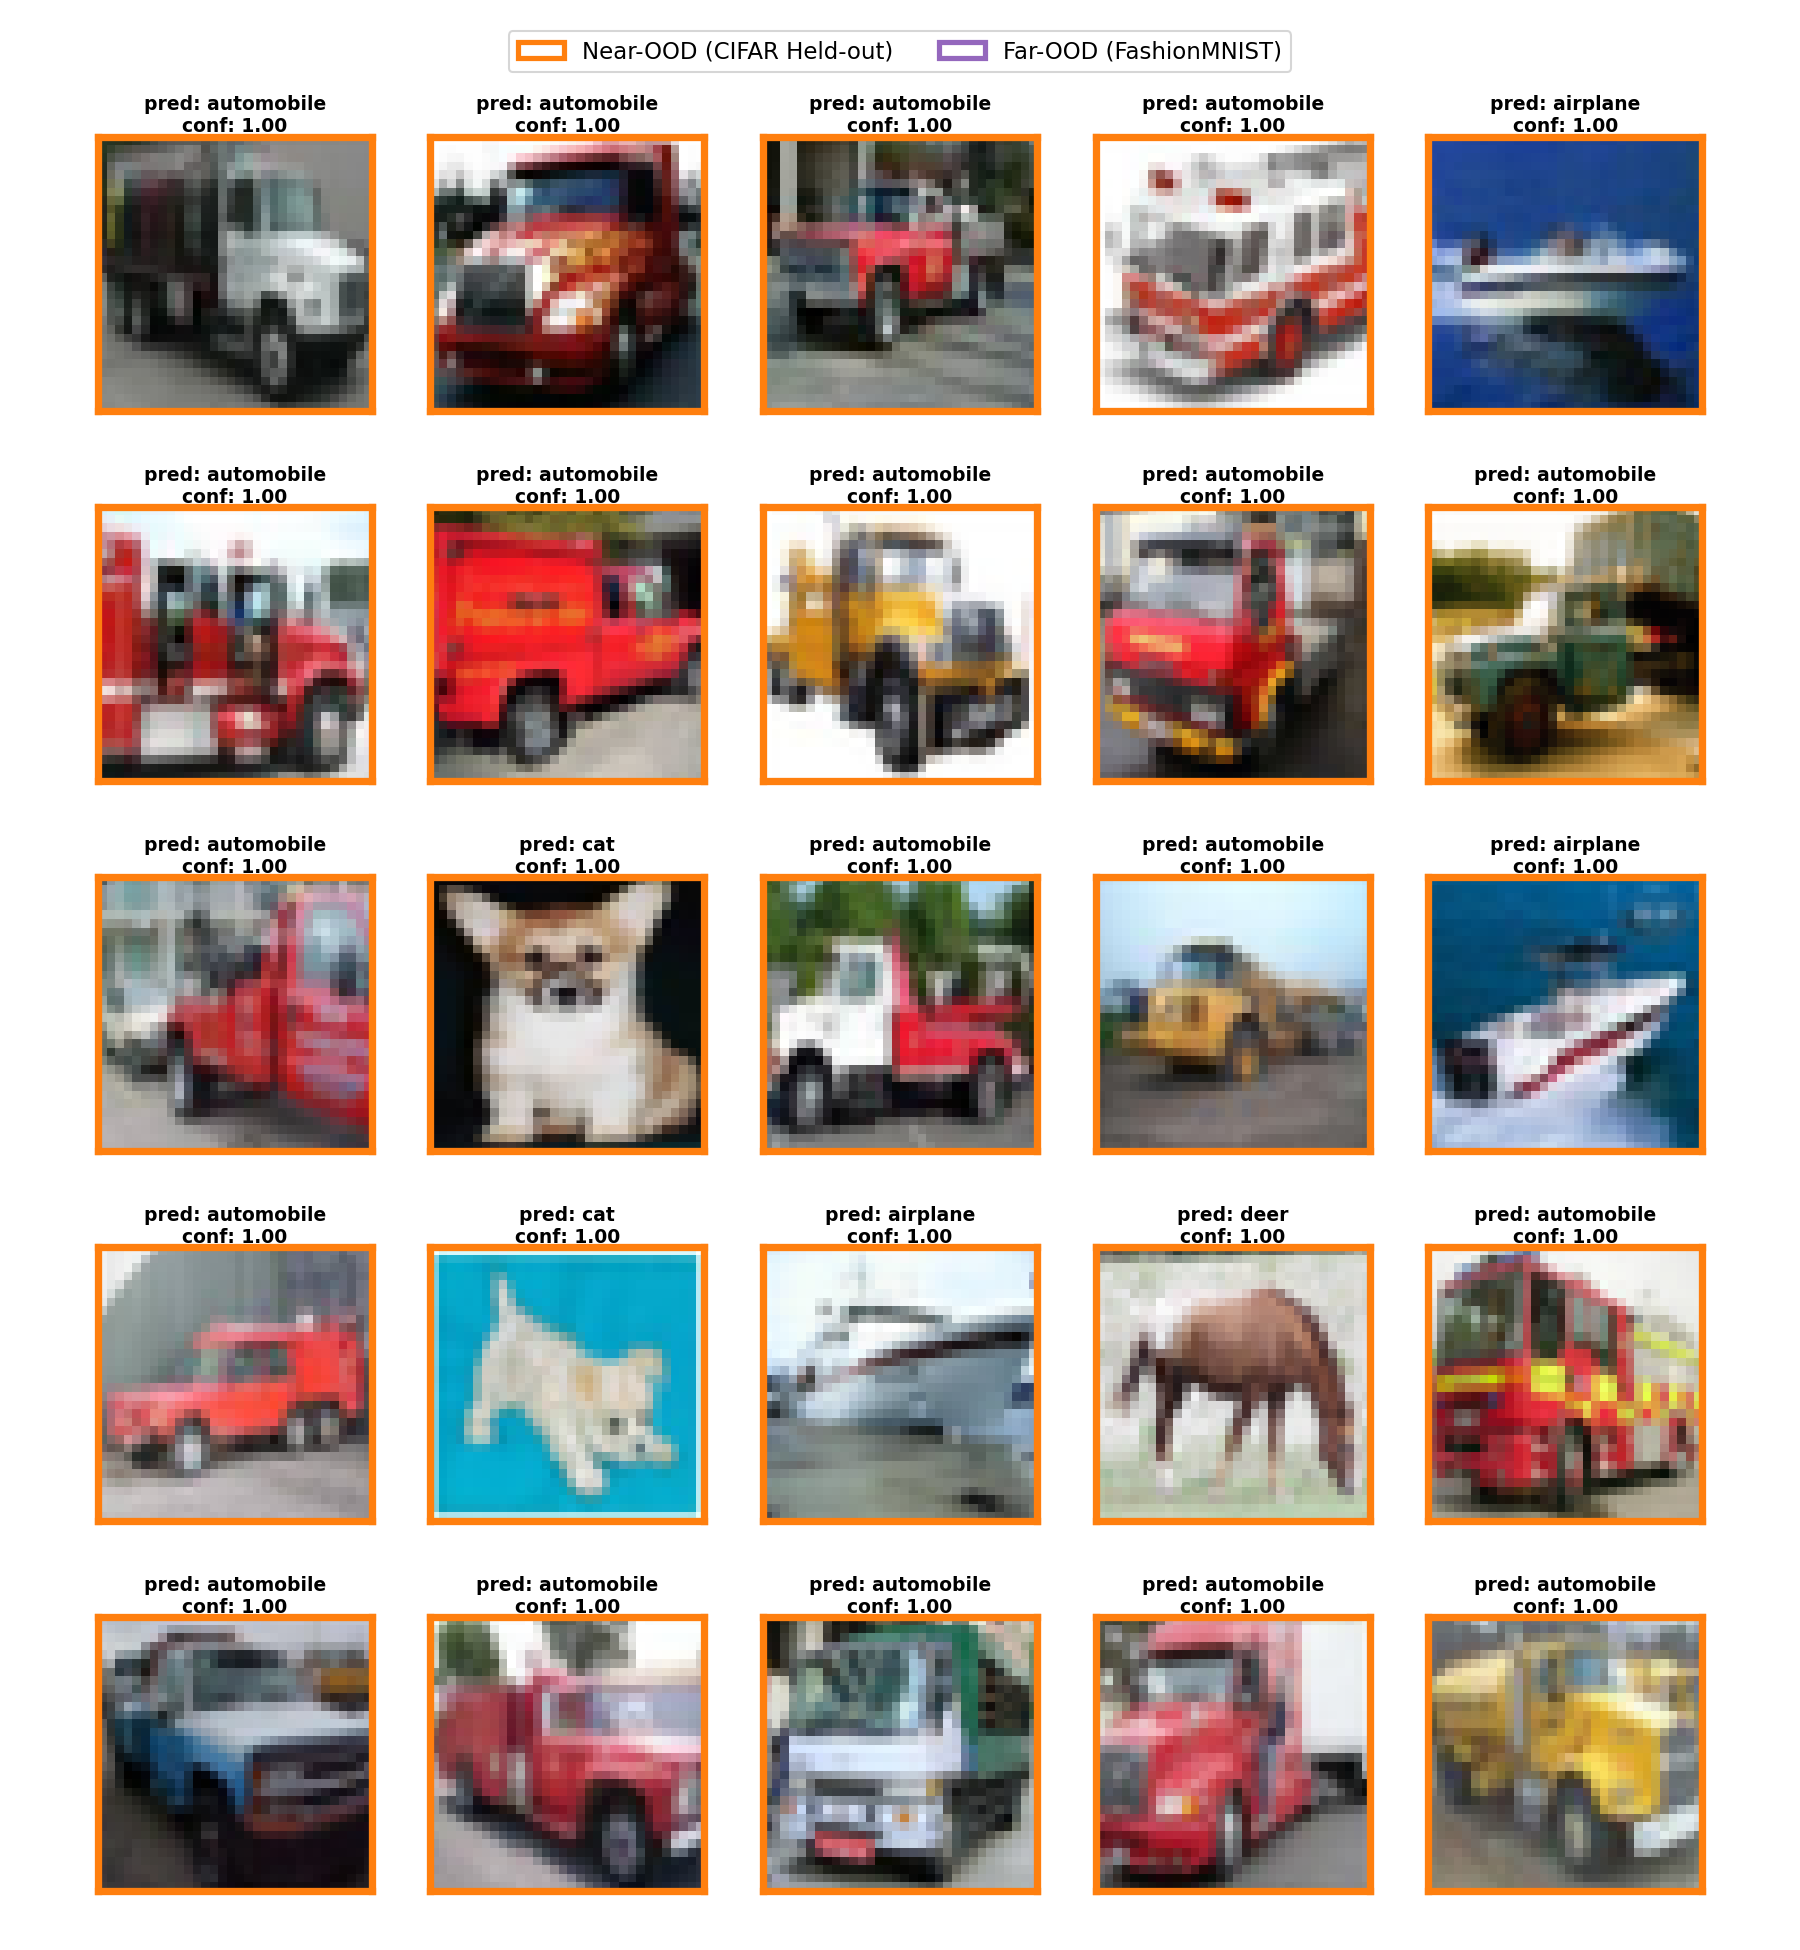

In [6]:
display(Image("figures/failure_gallery.png"))